Using Colab cache for faster access to the 'pima-indians-diabetes-database' dataset.

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


/tmp/ipykernel_437/3171272191.py:30: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].median(), inplace=True)


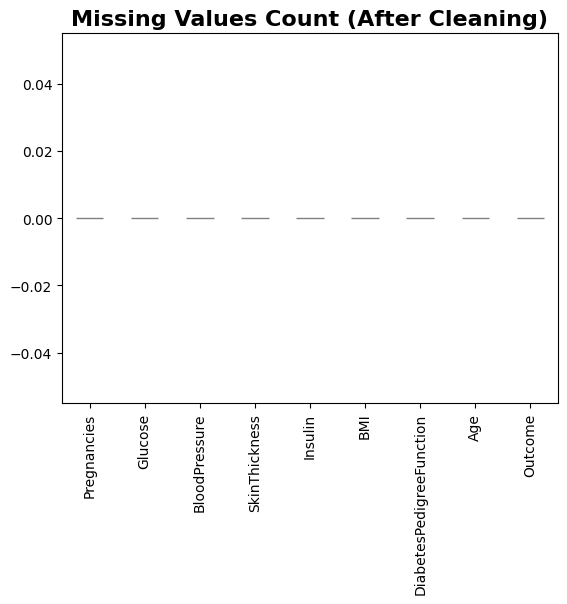

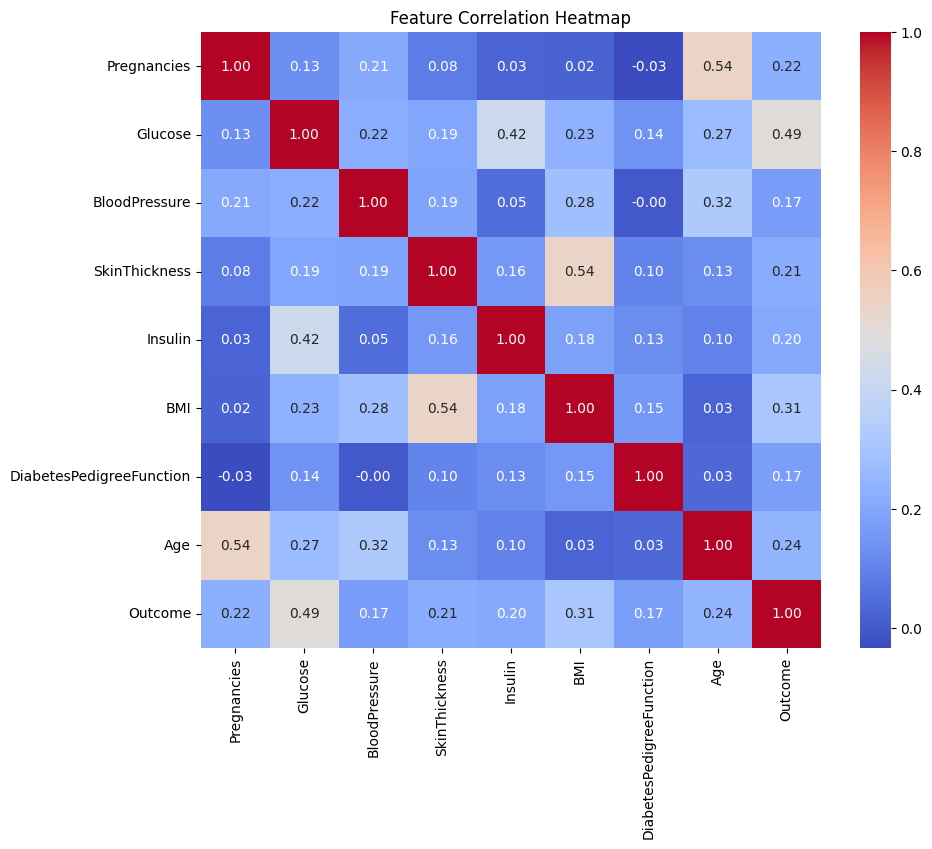


--- Logistic Regression Results ---
Accuracy: 0.75


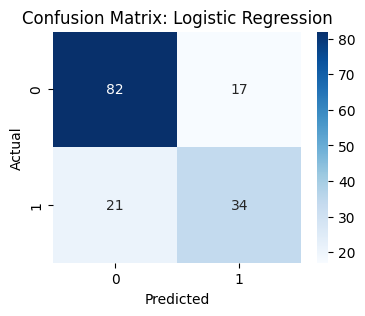


--- KNN Results ---
Accuracy: 0.72


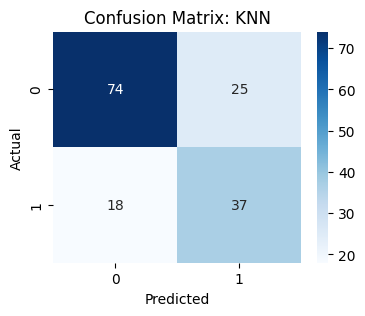


--- Decision Tree Results ---
Accuracy: 0.71


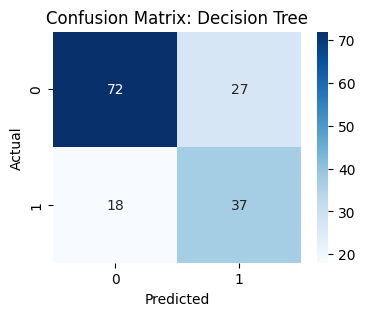


--- Random Forest Results ---
Accuracy: 0.77


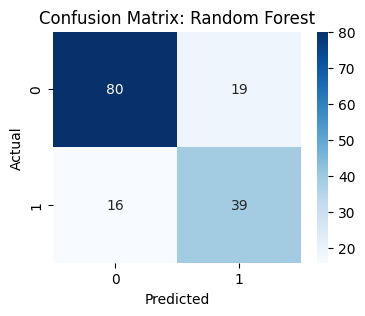


Model Comparison Table:
                 Model  Accuracy  Precision    Recall        F1
0  Logistic Regression  0.753247   0.666667  0.618182  0.641509
1                  KNN  0.720779   0.596774  0.672727  0.632479
2        Decision Tree  0.707792   0.578125  0.672727  0.621849
3        Random Forest  0.772727   0.672414  0.709091  0.690265


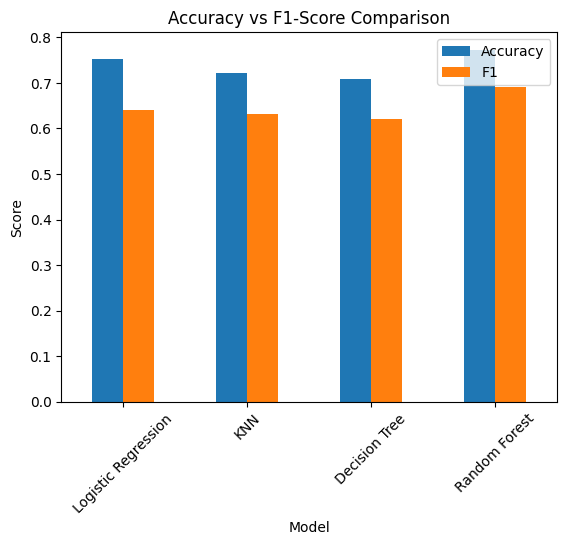

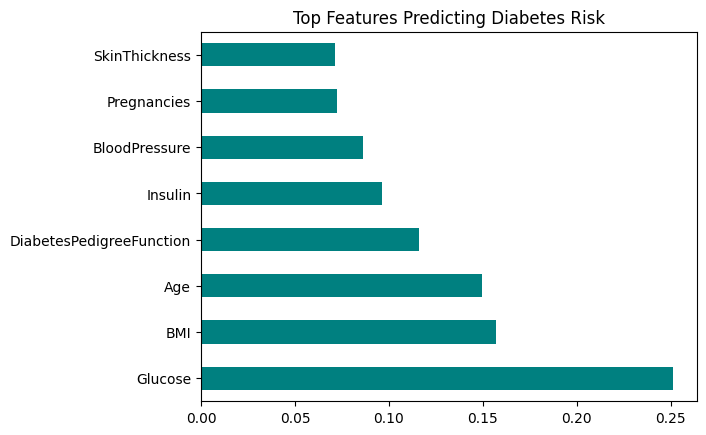

In [ ]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
# Using standard text formatting for simple numbers and units as per instructions
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score

# --- 1. DATA COLLECTION ---
# Download dataset from Kaggle
path = kagglehub.dataset_download("uciml/pima-indians-diabetes-database")
df = pd.read_csv(path + "/diabetes.csv")

print("\n--- Dataset Info ---")
df.info()

# --- 2. DATA CLEANING & EDA ---
# The dataset uses '0' to represent missing data in certain columns
import numpy as np
cols_with_zeros = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df[cols_with_zeros] = df[cols_with_zeros].replace(0, np.nan)

# Fill missing values with median (better for skewed clinical data)
for col in cols_with_zeros:
    df[col].fillna(df[col].median(), inplace=True)

# Visualize Missing Values (Should be zero now)
df.isnull().sum().plot(kind='bar', color='darkgray', edgecolor='gray')
plt.title("Missing Values Count (After Cleaning)", fontsize=16, fontweight='bold')
plt.show()

# EDA: Correlation Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Feature Correlation Heatmap")
plt.show()

# --- 3. TRAIN-TEST SPLIT & SCALING ---
X = df.drop('Outcome', axis=1)
y = df['Outcome']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# --- 4. MODEL BUILDING & EVALUATION ---
models = {
    "Logistic Regression": LogisticRegression(),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(),
    "Random Forest": RandomForestClassifier()
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    # Calculate required metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    results.append({"Model": name, "Accuracy": acc, "Precision": prec, "Recall": rec, "F1": f1})

    print(f"\n--- {name} Results ---")
    print(f"Accuracy: {acc:.2f}")

    # Display Confusion Matrix for each model
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(4,3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f"Confusion Matrix: {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

# --- 5. MODEL COMPARISON & INTERPRETATION ---
comparison_df = pd.DataFrame(results)
print("\nModel Comparison Table:")
print(comparison_df)

comparison_df.plot(kind='bar', x='Model', y=['Accuracy', 'F1'])
plt.title("Accuracy vs F1-Score Comparison")
plt.ylabel("Score")
plt.xticks(rotation=45)
plt.show()

# Feature Importance for Random Forest
rf_model = models["Random Forest"]
feat_importances = pd.Series(rf_model.feature_importances_, index=X.columns)
feat_importances.nlargest(10).plot(kind='barh', color='teal')
plt.title("Top Features Predicting Diabetes Risk")
plt.show()
